# 04 — Evaluation and Findings

Evaluate the trained models on the **same 10,000 July 2026 flights**.
Compare them with simple baselines, then inspect the selected model's mistakes.
The test results do not change the chosen model or its threshold.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'config/project.json').is_file())
OUT = ROOT/'reports/simple_reproduction'
OUT.mkdir(parents=True, exist_ok=True)

In [2]:
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (precision_score, recall_score, f1_score,
    accuracy_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, PrecisionRecallDisplay)
sns.set_theme(style='whitegrid')

Matplotlib is building the font cache; this may take a moment.


In [3]:
bundle = joblib.load(OUT/'models.joblib')
test = pd.read_parquet(OUT/'features.parquet').query("split == 'test'").sort_values('flight_id').reset_index(drop=True)
y = test['delayed_departure'].to_numpy(dtype=int)
assert len(test) == 10000 and test['flight_date'].between('2026-07-01', '2026-07-31').all()

## 1. Get scores and predictions

Most classifiers return delay probabilities; SVM returns decision scores.
Apply each model's saved threshold to turn its scores into predictions.

In [4]:
scores, thresholds = {}, {}
for key, item in bundle['models'].items():
    model = item['pipeline']
    X = test[item['columns']]
    scores[key] = model.decision_function(X) if key.startswith('svm__') else model.predict_proba(X)[:, 1]
    thresholds[key] = item['threshold']

### Simple baselines

Compare with always predicting on time, always predicting delayed, and a reproducible coin flip.
The historical baseline uses an earlier airline/airport delay rate, falling back to the airport rate
and then the original training delay rate (0.25705). Its threshold was chosen in the original study.

In [5]:
historical = test['history_airline_origin_rate'].fillna(test['history_origin_rate']).fillna(0.25705)
scores['always_on_time'] = np.zeros(len(test))
scores['always_delayed'] = np.ones(len(test))
scores['fair_coin_seed42'] = np.random.default_rng(42).integers(0, 2, len(test)).astype(float)
scores['historical_risk_ranking'] = historical.to_numpy(dtype=float)
thresholds.update({name: .5 for name in ['always_on_time', 'always_delayed', 'fair_coin_seed42']})
baseline_settings = json.loads((ROOT/'reports/model_selection.json').read_text())
thresholds['historical_risk_ranking'] = baseline_settings['baselines']['historical_risk_ranking']['threshold']

## 2. Compare performance

- **Accuracy:** fraction of all predictions that are correct.
- **Precision:** among delay warnings, the fraction actually delayed.
- **Recall:** among delayed flights, the fraction detected.
- **F1:** balances precision and recall.
- **Average precision (AP):** measures how well scores rank delays across thresholds.

In [6]:
def performance(y, prediction, score):
    return [accuracy_score(y, prediction),
            precision_score(y, prediction, zero_division=np.nan),
            recall_score(y, prediction),
            f1_score(y, prediction),
            average_precision_score(y, score)]

In [7]:
rows = []
for key, score in scores.items():
    prediction = score >= thresholds[key]
    model, inputs = key.split('__') if '__' in key else (key, 'baseline')
    rows.append([model, inputs] + performance(y, prediction, score))
metric_names = ['accuracy', 'precision', 'recall', 'f1', 'average_precision']
metrics = pd.DataFrame(rows, columns=['model_id', 'feature_set'] + metric_names)
display(metrics.round(4))

,model_id,feature_set,accuracy,precision,recall,f1,average_precision
0,logistic_regression,A,0.3701,0.3362,0.9844,0.5012,0.5041
1,logistic_regression,B,0.4929,0.3810,0.9241,0.5395,0.5665
2,knn,A,0.4282,0.3533,0.9375,0.5132,0.4657
3,knn,B,0.5425,0.4007,0.8535,0.5454,0.5324
4,svm,A,0.3215,0.3215,1.0000,0.4866,0.4818
5,svm,B,0.6118,0.4349,0.6924,0.5342,0.5130
6,random_forest,A,0.5384,0.3975,0.8445,0.5405,0.4928
7,random_forest,B,0.5237,0.3926,0.8796,0.5429,0.5404
8,always_on_time,baseline,0.6785,NaN,0.0000,0.0000,0.3215
9,always_delayed,baseline,0.3215,0.3215,1.0000,0.4866,0.3215


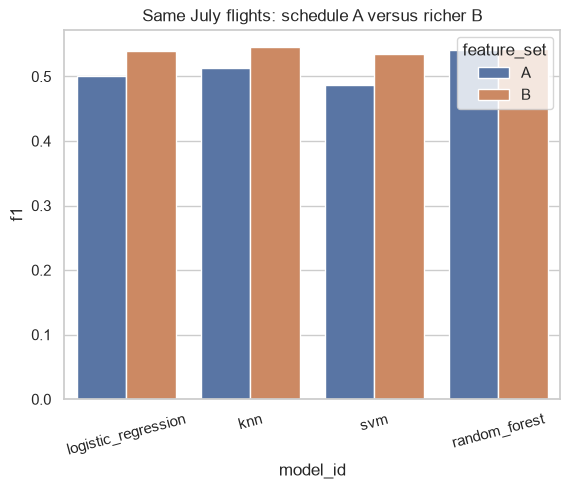

In [8]:
sns.barplot(data=metrics.query("feature_set != 'baseline'"), x='model_id', y='f1', hue='feature_set')
plt.title('Same July flights: schedule A versus richer B')
plt.xticks(rotation=15)
plt.show()

**Finding 1:** Always predicting on time reaches **67.85% accuracy**, but detects no delays (F1 = 0).
Accuracy alone would hide this failure. A random ranking has AP equal to the delay prevalence, **32.15%**.

**Finding 2:** Richer inputs improve ranking. Logistic Regression B gains about **0.062 AP** and
**0.038 F1** over its schedule-only version. The extra features provide information beyond the schedule.
This comparison does not isolate the individual effects of weather, history and traffic.

## 3. Inspect the selected model's mistakes

The confusion matrix compares actual outcomes (rows) with predictions (columns).

In [9]:
chosen = bundle['selected_model_id'] + '__B'
prediction = scores[chosen] >= thresholds[chosen]
print(classification_report(y, prediction, target_names=['On time', 'Delayed'], digits=3))

              precision    recall  f1-score   support

     On time      0.889     0.289     0.436      6785
     Delayed      0.381     0.924     0.540      3215

    accuracy                          0.493     10000
   macro avg      0.635     0.606     0.488     10000
weighted avg      0.726     0.493     0.469     10000



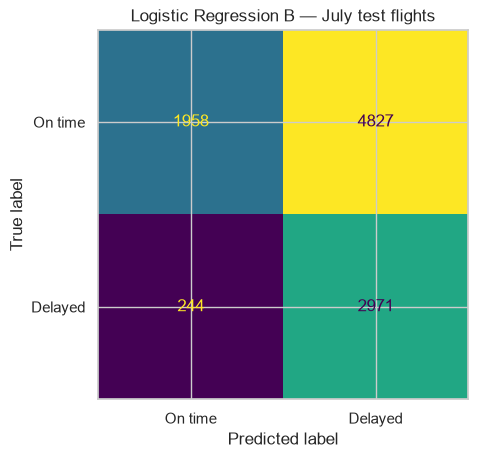

In [10]:
ConfusionMatrixDisplay.from_predictions(y, prediction, display_labels=['On time', 'Delayed'], colorbar=False)
plt.title('Logistic Regression B — July test flights')
plt.show()

**Finding 3:** Logistic Regression B detects **2,971 delays** and misses **244**, but raises **4,827 false warnings**.
Its recall is **92.4%** and precision **38.1%**. Catching most delays comes at the cost of many false warnings.

## 4. Compare precision and recall across thresholds

The curves show the trade-off as the threshold changes. They describe the test results;
we do not use them to choose a new threshold.

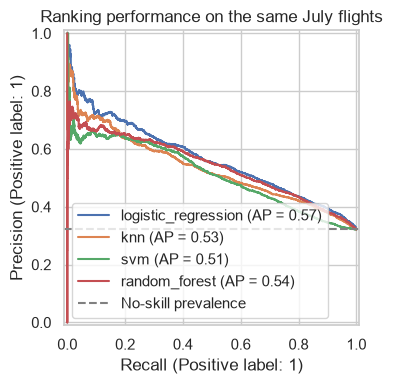

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
for key in [key for key in scores if key.endswith('__B')]:
    PrecisionRecallDisplay.from_predictions(y, scores[key], name=key.split('__')[0], ax=ax)
ax.axhline(y.mean(), color='grey', linestyle='--', label='No-skill prevalence')
ax.legend()
plt.title('Ranking performance on the same July flights')
plt.tight_layout()
plt.show()

## Save results and note the limitations

This is one summer month at three airports. Cancelled flights and unknown outcomes are outside the target.
Weather availability and historical reporting delays are assumptions, and the scores are not calibrated probabilities.
July has already been inspected, so it is not untouched evidence for another round of tuning.

The existing [report](../../reports/final_report/output/pdf/predeparture_flight_delay_report.pdf)
contains the additional subgroup, review-budget and bootstrap analyses from the completed study.

In [12]:
metrics.to_json(OUT/'metrics.json', orient='records', indent=2, double_precision=15)
np.savez_compressed(OUT/'scores.npz', **scores)

[Notebook guide](../../md/notebooks/simple/README.md)